In [ ]:
import tensorflow as tf
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd



In [ ]:
#load the dataset of mnist
(xtrain,ytrain),(xtest,ytest)=tf.keras.datasets.mnist.load_data()

In [ ]:
print(xtrain.shape)# checing shpe of each dataset 60k img for size 28,28 pixels
print(ytrain.shape)
print(xtest.shape)
print(ytest.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [ ]:
print(type(xtrain))#checking type of each data
print(type(ytrain))
print(type(xtest))
print(type(ytest))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [ ]:
print(xtrain.dtype)# checing datatype of each dataset unsigned 8 bit int so 2**8 possible indexes
print(ytrain.dtype)
print(xtest.dtype)
print(ytest.dtype)

uint8
uint8
uint8
uint8


In [ ]:
print(xtrain.max())
print(ytrain.max())
print(xtest.max())
print(ytest.max())
print(xtrain.min())
print(ytrain.min())
print(xtest.min())
print(ytest.min())

255
9
255
9
0
0
0
0


In [ ]:
print(f'pixel range(xtrain):({xtrain.min()},{xtrain.max()})')
print(f'pixel range(xtest):({xtest.min()},{xtest.max()})')

pixel range(xtrain):(0,255)
pixel range(xtest):(0,255)


In [ ]:
print('unique labels counts',len(set(ytrain)))
print('unique labels counts',len(set(ytest)))
print('unique labels ',set(ytrain))
print('unique labels ',set(ytest))

unique labels counts 10
unique labels counts 10
unique labels  {np.uint8(0), np.uint8(1), np.uint8(2), np.uint8(3), np.uint8(4), np.uint8(5), np.uint8(6), np.uint8(7), np.uint8(8), np.uint8(9)}
unique labels  {np.uint8(0), np.uint8(1), np.uint8(2), np.uint8(3), np.uint8(4), np.uint8(5), np.uint8(6), np.uint8(7), np.uint8(8), np.uint8(9)}


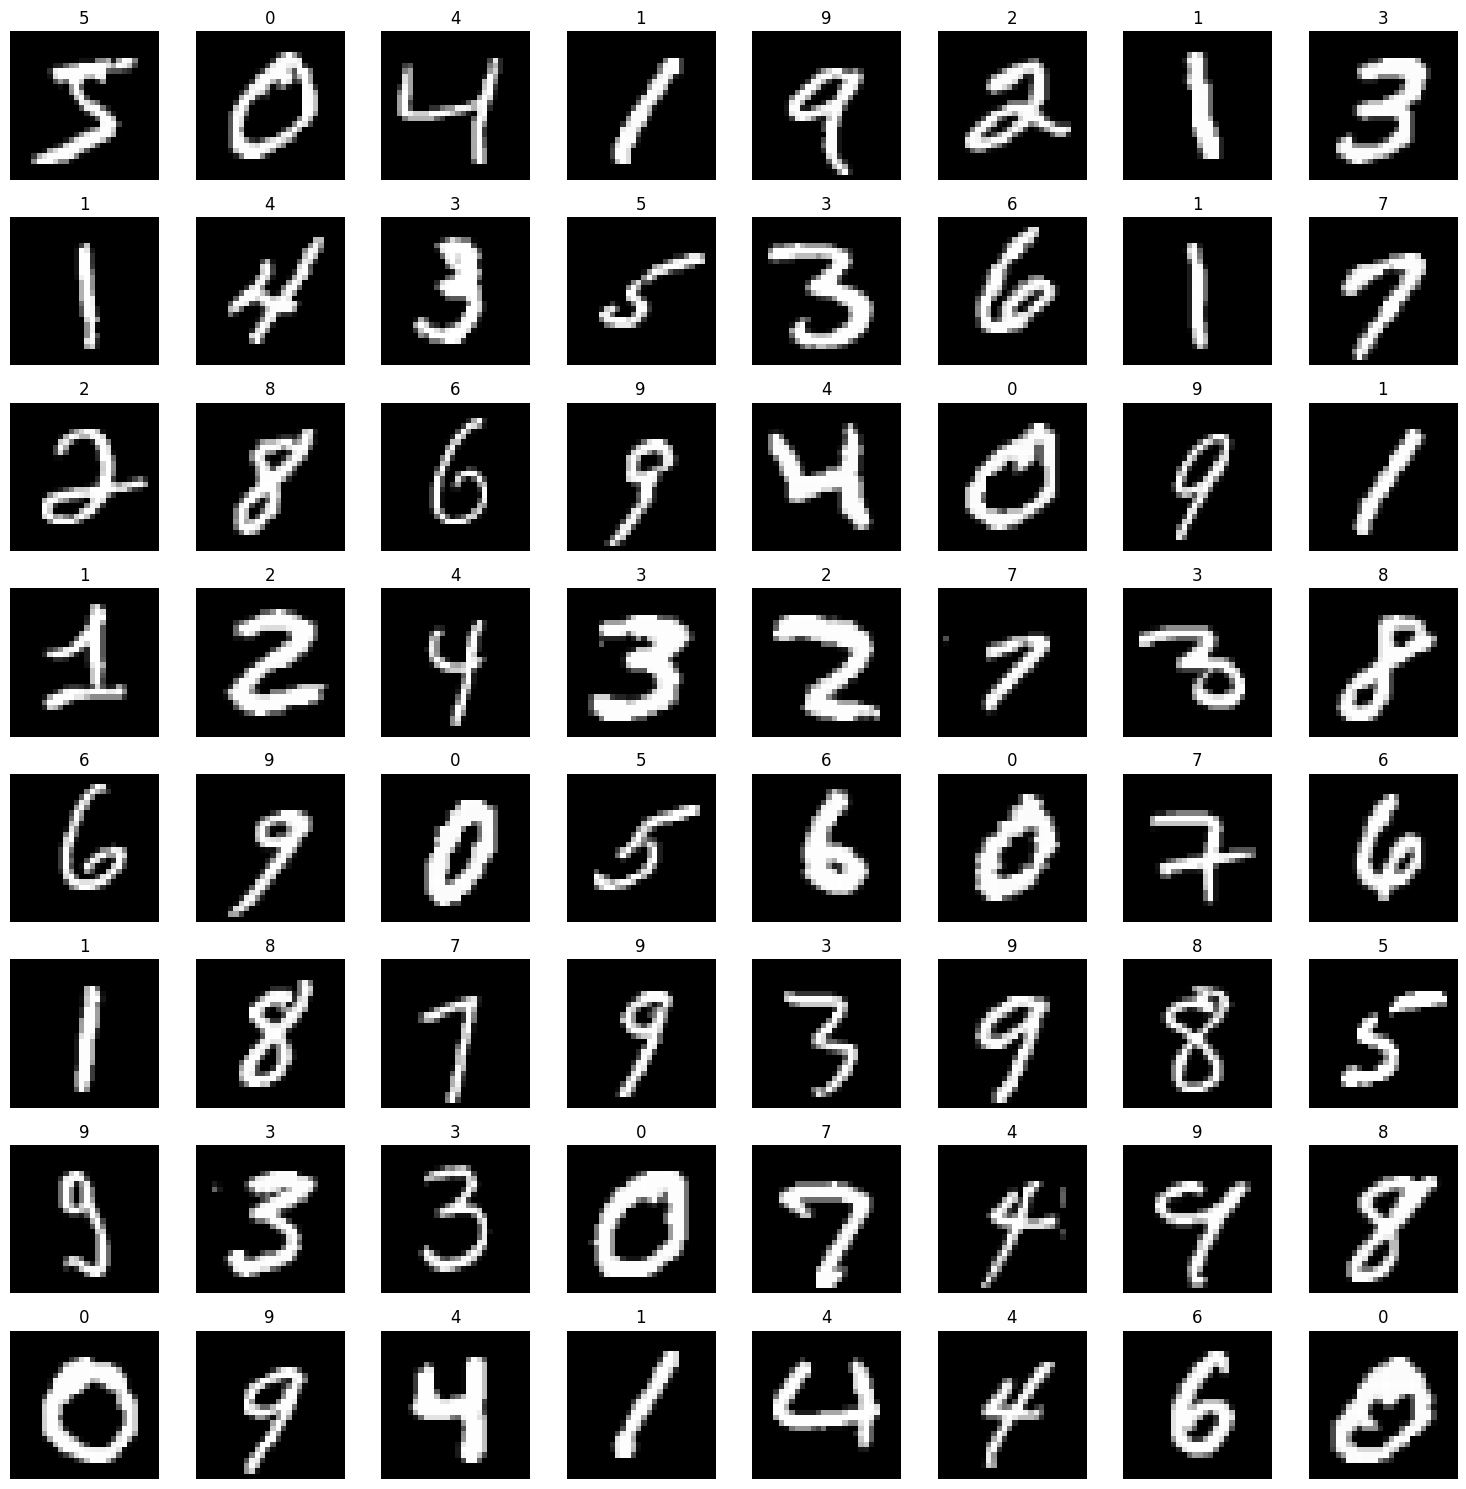

In [ ]:
plt.figure(figsize=(15,15))
for index in range(64):
  plt.subplot(8,8,index+1)# 8 row 8 col
  plt.imshow(xtrain[index],cmap='gray')
  plt.axis('off')
  plt.title(ytrain[index])
  plt.grid()


plt.tight_layout()

plt.show()


In [ ]:
#scale pixel to 0 and 1
from re import X
X_train_std=(xtrain-xtrain.min())/(xtrain.max()-xtrain.min())
X_train_scaled=X_train_std*(1-0)+0
X_test_std=(xtest-xtest.min())/(xtest.max()-xtest.min())
X_test_scaled=X_test_std*(1-0)+0


In [ ]:
print(f' range(xtest):({X_test_std.min()},{X_test_std.max()})')
print(f' range(xtest):({X_test_scaled.min()},{X_test_scaled.max()})')


 range(xtest):(0.0,1.0)
 range(xtest):(0.0,1.0)


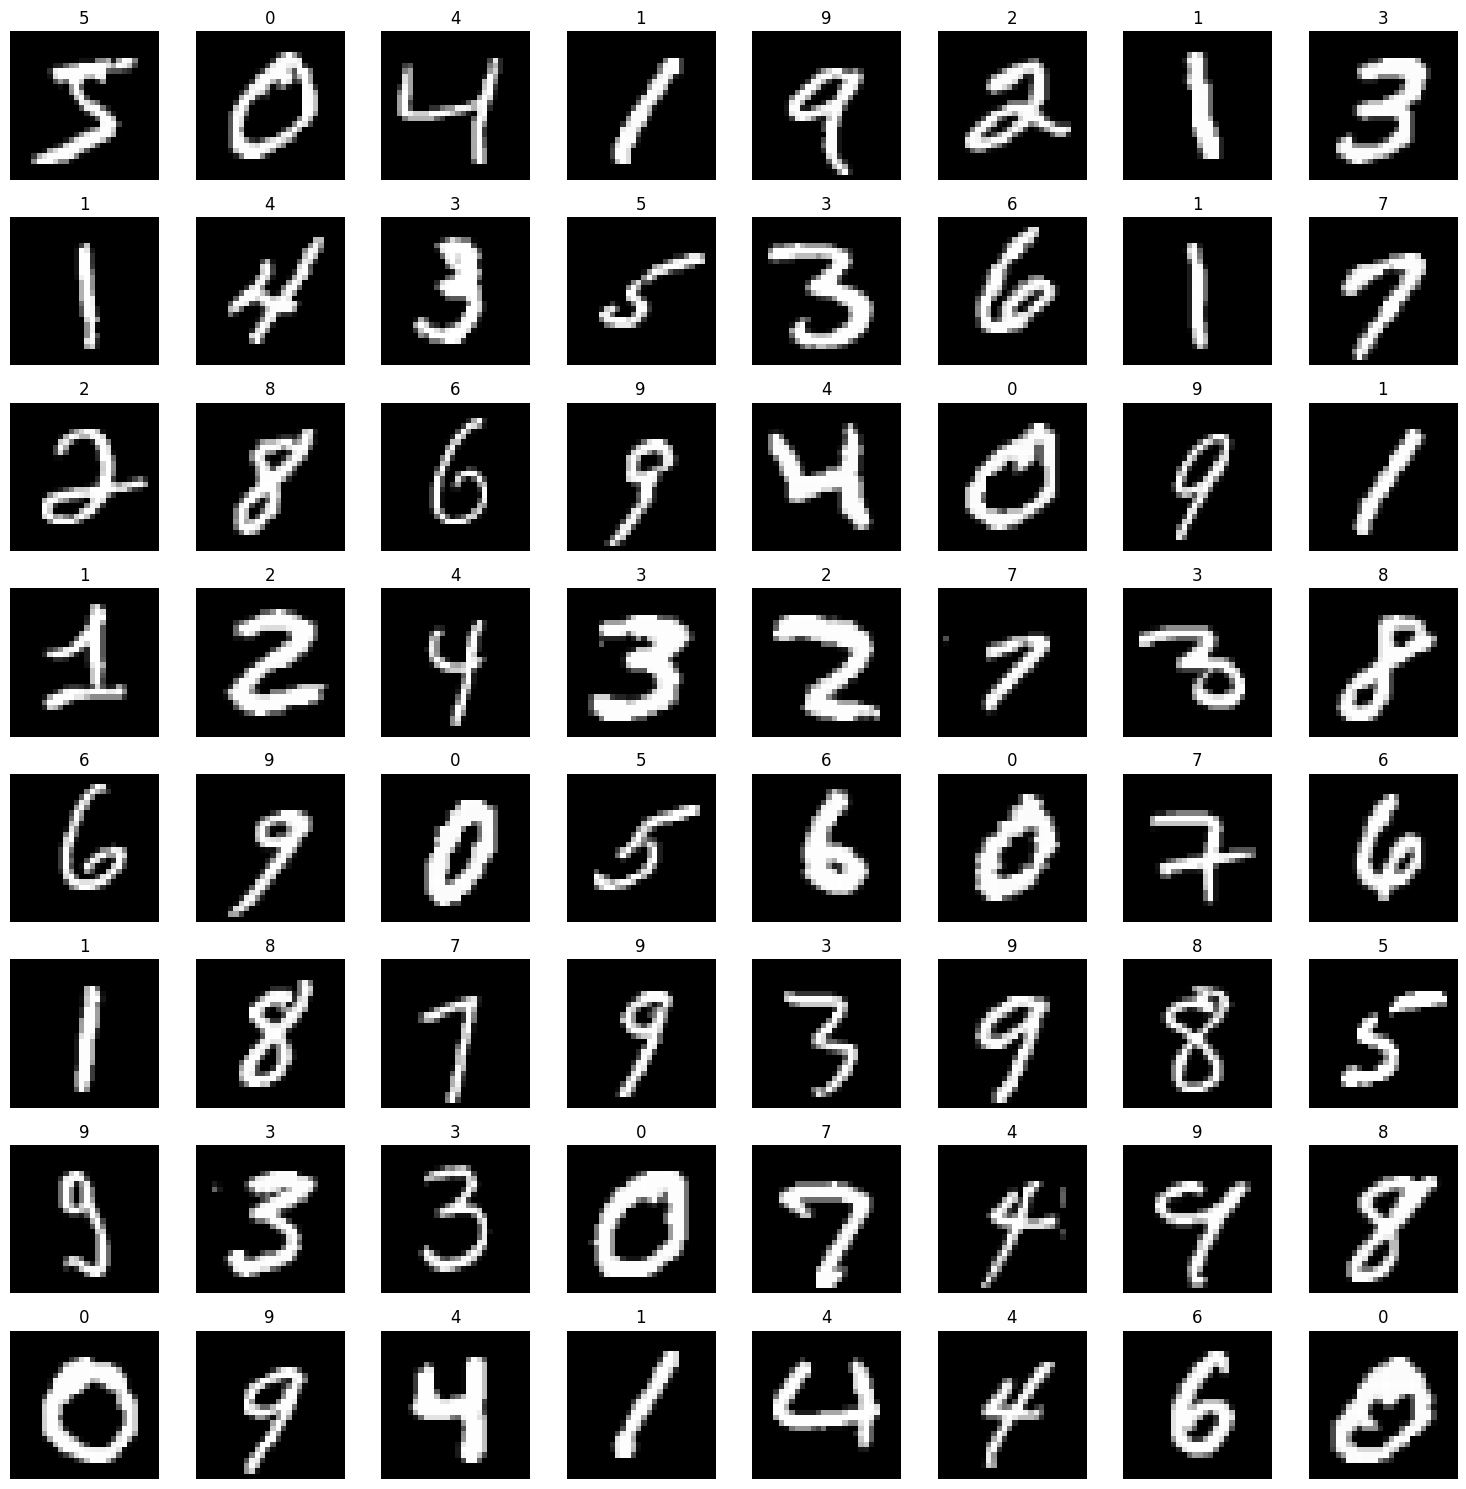

In [ ]:
plt.figure(figsize=(15,15))
for index in range(64):
  plt.subplot(8,8,index+1)# 8 row 8 col
  plt.imshow(X_train_scaled[index],cmap='gray')
  plt.axis('off')
  plt.title(ytrain[index])
  plt.grid()


plt.tight_layout()

plt.show()


In [ ]:
inputs=tf.keras.layers.Input(shape=(28,28))# designing the input layer
modelx=tf.keras.layers.Flatten()(inputs)#flatten the input layer as input layer is an numpy 2d array use flatten for fast speeds
modelx=tf.keras.layers.Dense(128,activation='relu')(modelx)# for making 1st hidden layer of size 128
modelx=tf.keras.layers.Dense(64,activation='relu')(modelx)# for making 2nd hidden layer of size 64
modelx=tf.keras.layers.Dense(32,activation='relu')(modelx)# for making 3rd hidden layer of size 32# relu converts -ve weight to 0 and rest as it is
outputs=tf.keras.layers.Dense(10,activation='softmax')(modelx)# for making output layer of size 10# softmax gives probabilistic output


model=tf.keras.models.Model(inputs=inputs,outputs=outputs)# model=tf.keras.models.Model(inputs=inputs,outputs=modelx) for model layer for final output layer it is changed to outputs
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,146 (434.16 KB)

 Trainable params: 111,146 (434.16 KB)

 Non-trainable params: 0 (0.00 B)

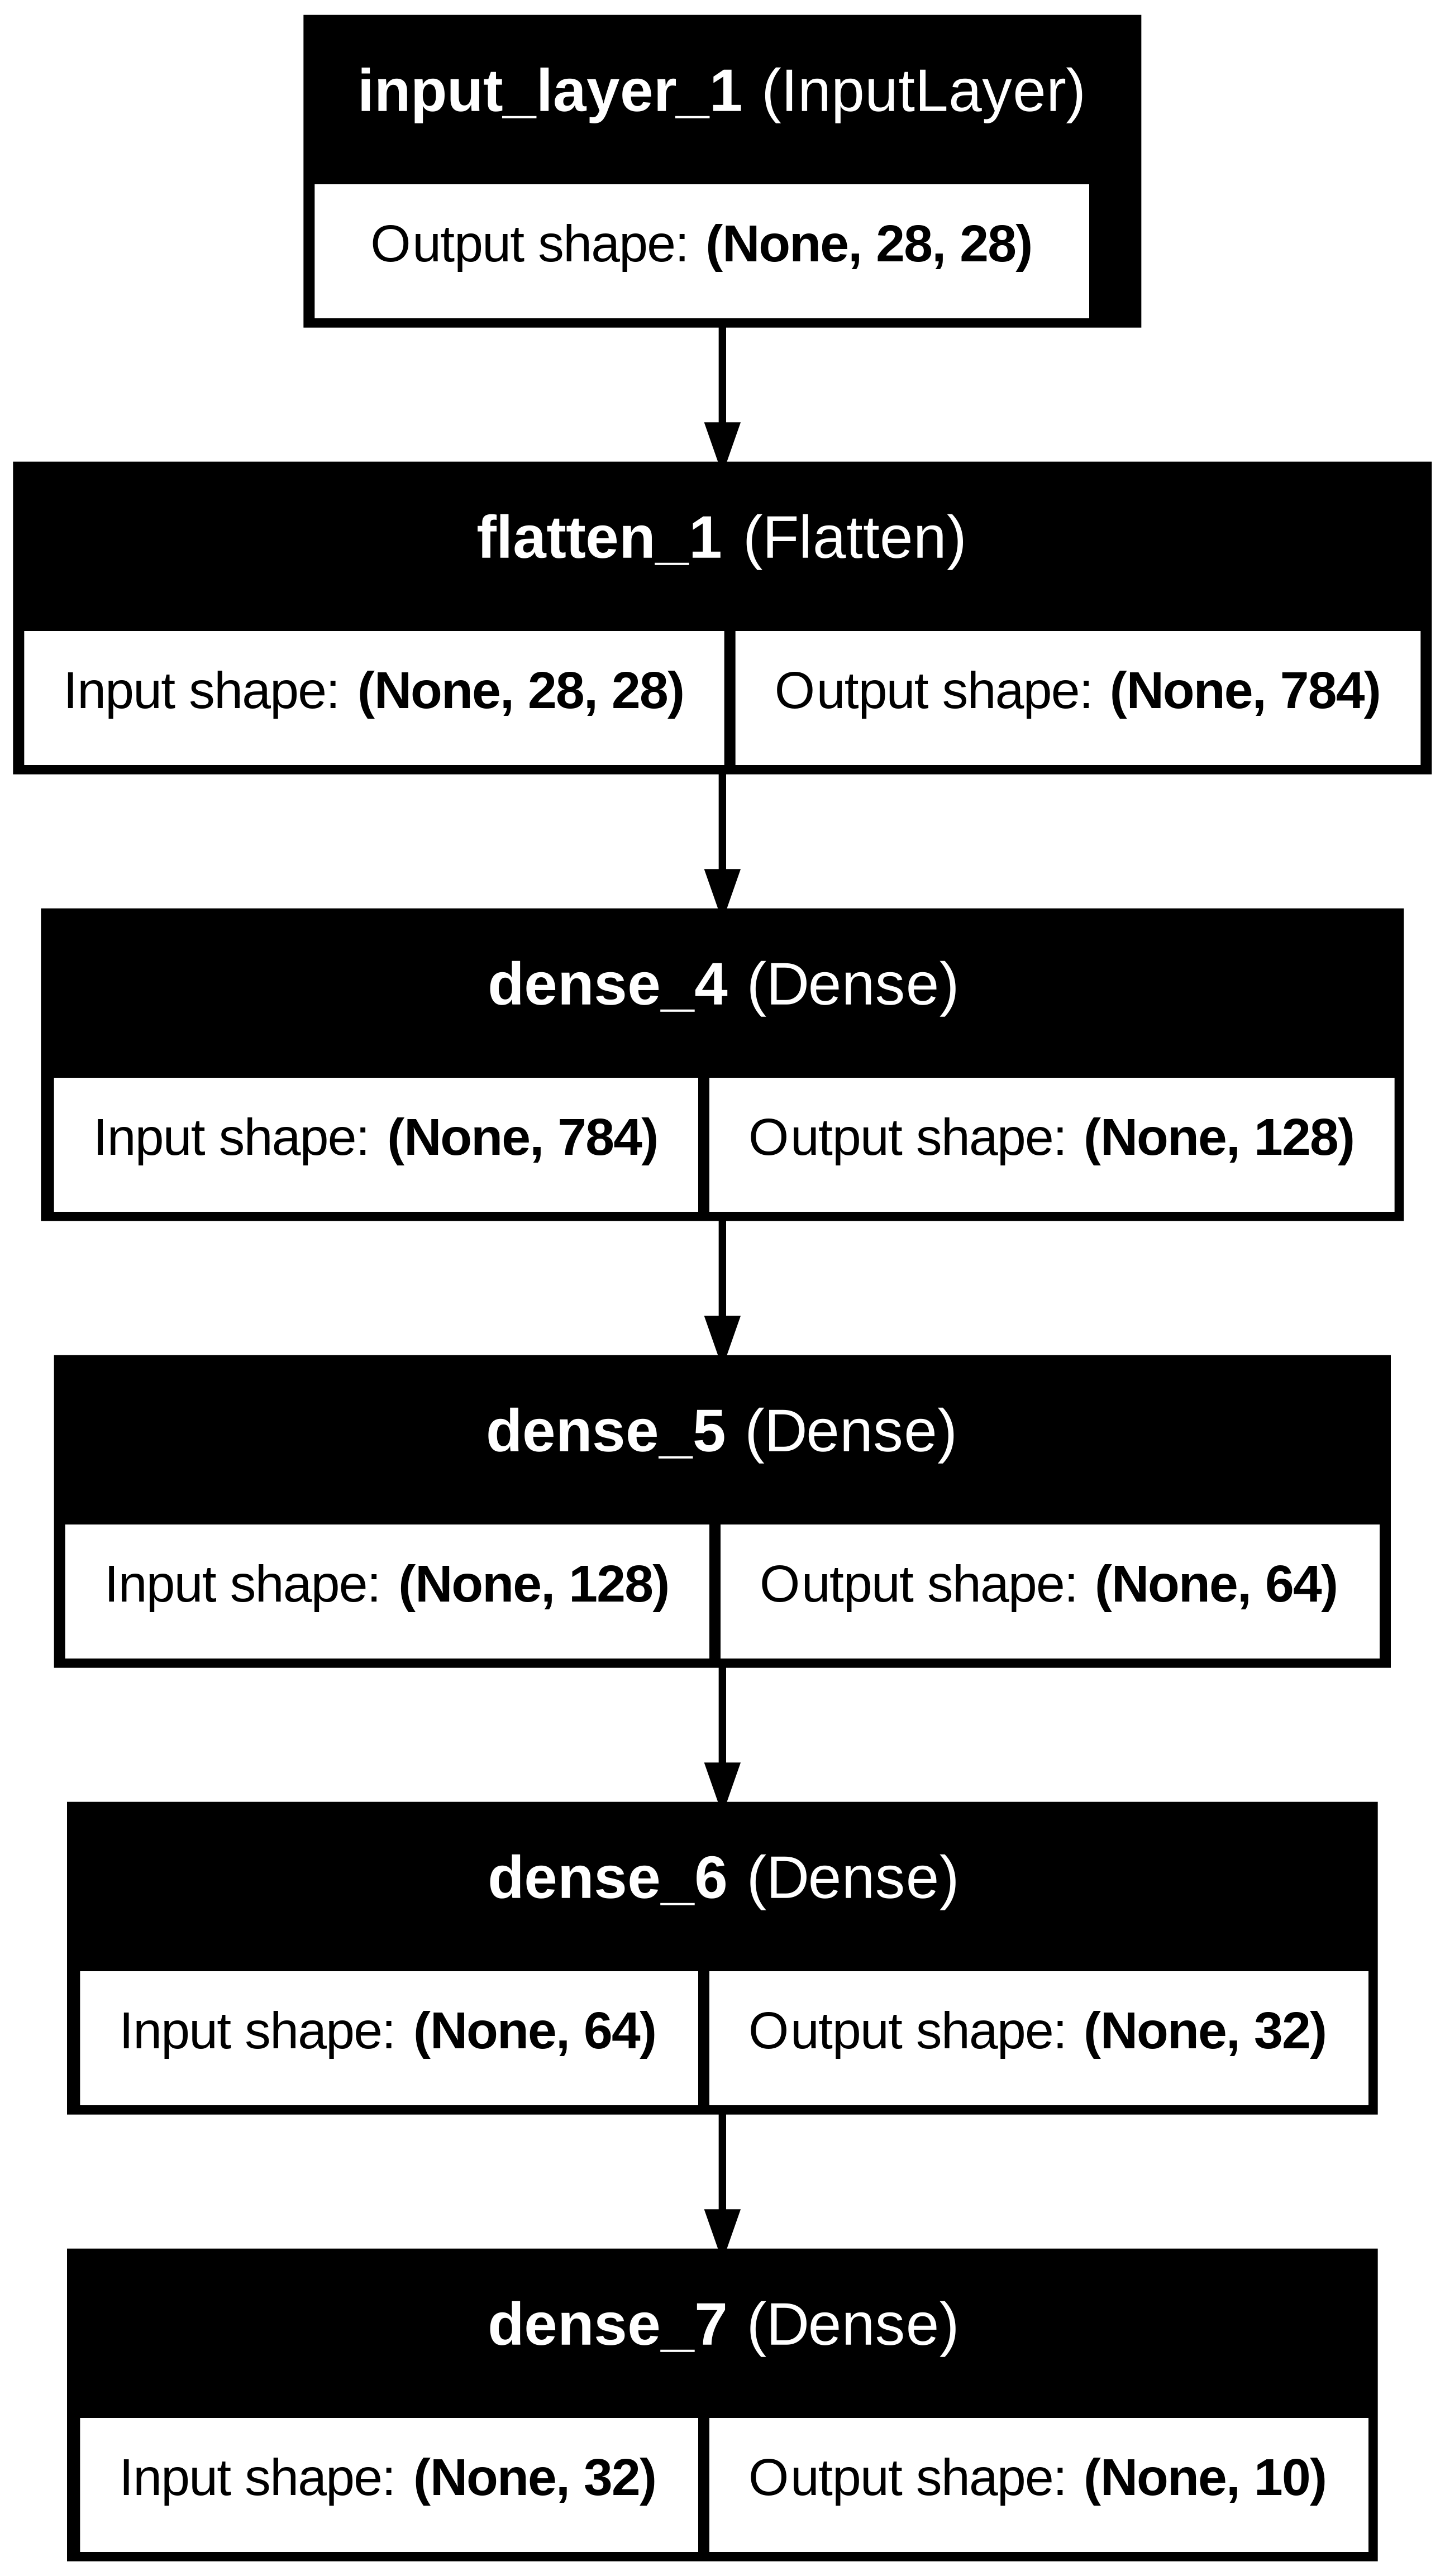

In [ ]:
tf.keras.utils.plot_model(model,to_file='model.png',show_shapes=True,show_layer_names=True,dpi=480)

In [ ]:
model.compile(optimizer=tf.keras.optimizers.Adam(),loss=tf.keras.losses.SparseCategoricalCrossentropy(),metrics=[tf.keras.metrics.SparseCategoricalAccuracy()])
# the model is compiled

In [ ]:
xtrain[:5].shape

(5, 28, 28)

In [ ]:
ytrain[:5]

array([5, 0, 4, 1, 9], dtype=uint8)

In [ ]:
tf.math.round(model.predict(xtrain[:5]),5)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step


<tf.Tensor: shape=(5, 10), dtype=float32, numpy=
array([[0., 0., 0., 0., 0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 1., 0.]], dtype=float32)>

In [ ]:
early_stopping=tf.keras.callbacks.EarlyStopping(monitor='val_loss',mode='auto',patience=10,verbose=1,restore_best_weights=True)# this is the backend entity to control the epochs , monitor holds parameter to stop,
history=model.fit(xtrain,ytrain,batch_size=128,epochs=10000,callbacks=[early_stopping],verbose='auto',validation_data=(xtest,ytest))# model is trained out of 60 k images we go by each batch of 128 img so we get 469 batches , epoch is responsible how many times the loop works, verbose means controlling the output as printing is slow  0 means no printing only processing

Epoch 1/10000
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 1.7931 - sparse_categorical_accuracy: 0.7742 - val_loss: 0.4945 - val_sparse_categorical_accuracy: 0.8740
Epoch 2/10000
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3992 - sparse_categorical_accuracy: 0.9030 - val_loss: 0.3703 - val_sparse_categorical_accuracy: 0.9082
Epoch 3/10000
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2706 - sparse_categorical_accuracy: 0.9326 - val_loss: 0.2493 - val_sparse_categorical_accuracy: 0.9378
Epoch 4/10000
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2042 - sparse_categorical_accuracy: 0.9482 - val_loss: 0.2253 - val_sparse_categorical_accuracy: 0.9477
Epoch 5/10000
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1634 - sparse_categorical_accuracy: 0.9572 - val_loss: 0.2364 - val_sparse_categorical_accuracy: 0.9498
Epoch 6/10000
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1396 - sparse_categorical_accuracy: 0.9622 - val_loss: 0.1819 - val_sparse_categorical_acc

In [ ]:
type(history.history)

dict

In [ ]:
history_df=pd.DataFrame(history.history)
history_df.head()

,loss,sparse_categorical_accuracy,val_loss,val_sparse_categorical_accuracy
0,1.793074,0.774183,0.494485,0.8740
1,0.399240,0.903033,0.370269,0.9082
2,0.270569,0.932550,0.249314,0.9378
3,0.204239,0.948167,0.225348,0.9477
4,0.163350,0.957167,0.236358,0.9498


In [ ]:
history_df.tail()

,loss,sparse_categorical_accuracy,val_loss,val_sparse_categorical_accuracy
31,0.019618,0.994417,0.144437,0.9732
32,0.024085,0.992850,0.156854,0.9711
33,0.018508,0.994367,0.165766,0.9752
34,0.019074,0.994083,0.158284,0.9749
35,0.019887,0.994433,0.165592,0.9719


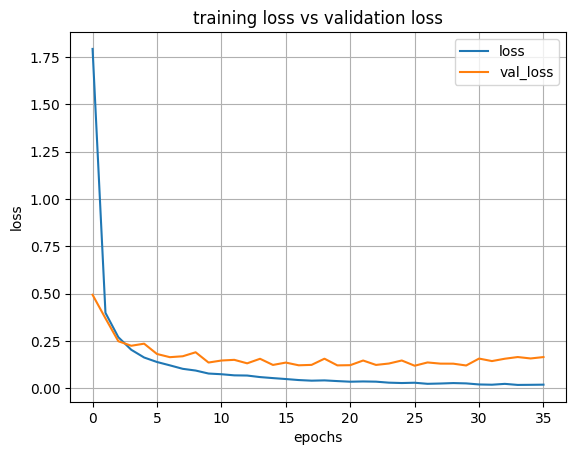

In [ ]:
history_df[['loss','val_loss']].plot()
plt.xlabel('epochs')
plt.ylabel('loss')
plt.title('training loss vs validation loss')
plt.grid()
plt.show()

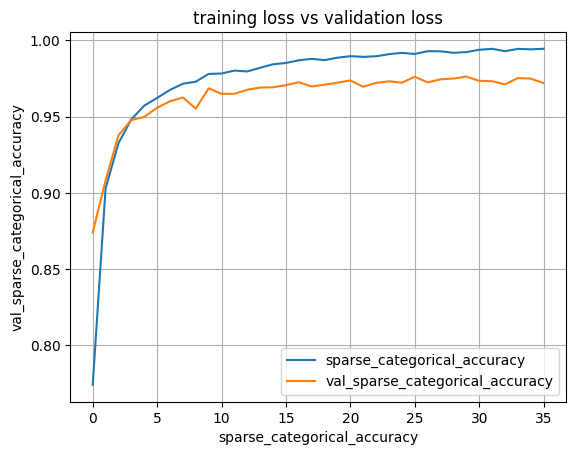

In [ ]:
history_df[['sparse_categorical_accuracy','val_sparse_categorical_accuracy']].plot()
plt.xlabel('sparse_categorical_accuracy')
plt.ylabel('val_sparse_categorical_accuracy')
plt.title('')
plt.grid()
plt.show()

In [ ]:
results=model.evaluate(xtrain,ytrain,return_dict=True)
print('test loss,test accuracy',results)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.0192 - sparse_categorical_accuracy: 0.9945
test loss,test accuracy {'loss': 0.01920393854379654, 'sparse_categorical_accuracy': 0.9944833517074585}


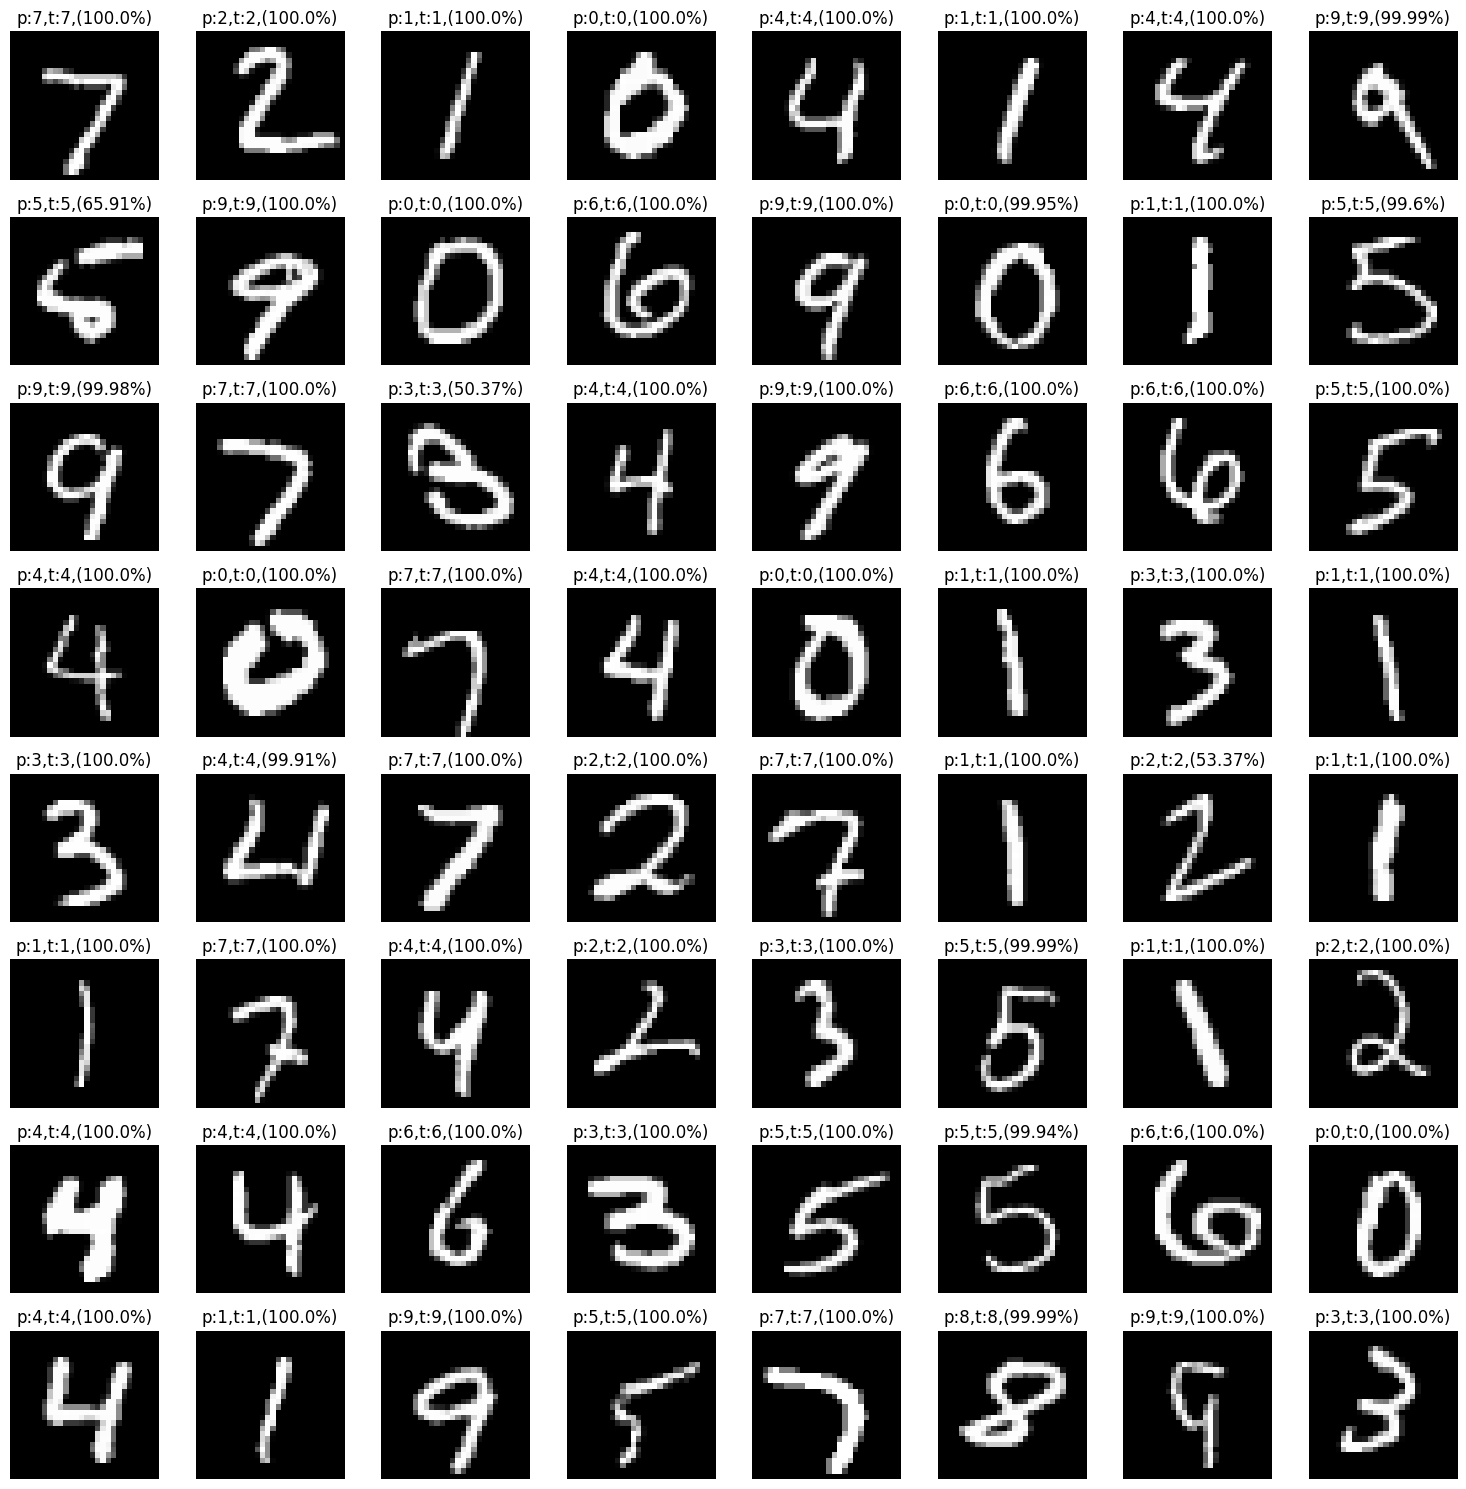

In [ ]:
plt.figure(figsize=(15,15))
for index in range(64):
  plt.subplot(8,8,index+1)# 8 row 8 col
  plt.imshow(xtest[index],cmap='gray')
  logistic=model.predict(xtest[index:index+1],verbose=0)
  label=tf.argmax(logistic,axis=1)[0]
  prob=round(float(tf.reduce_max(logistic))*100,2)
  plt.axis('off')
  plt.title(f'p:{ytest[index]},t:{label},({prob}%)')# get title
  plt.grid()


plt.tight_layout()
plt.show()
